![A soccer pitch for an international match.](soccer-pitch.jpg)

You're working as a sports journalist at a major online sports media company, specializing in soccer analysis and reporting. You've been watching both men's and women's international soccer matches for a number of years, and your gut instinct tells you that more goals are scored in women's international football matches than men's. This would make an interesting investigative article that your subscribers are bound to love, but you'll need to perform a valid statistical hypothesis test to be sure!

While scoping this project, you acknowledge that the sport has changed a lot over the years, and performances likely vary a lot depending on the tournament, so you decide to limit the data used in the analysis to only official `FIFA World Cup` matches (not including qualifiers) since `2002-01-01`.

You create two datasets containing the results of every official men's and women's international football match since the 19th century, which you scraped from a reliable online source. This data is stored in two CSV files: `women_results.csv` and `men_results.csv`.

The question you are trying to determine the answer to is:

> Are more goals scored in women's international soccer matches than men's?

You assume a **10% significance level**, and use the following null and alternative hypotheses:

$H_0$ : The mean number of goals scored in women's international soccer matches is the same as men's.

$H_A$ : The mean number of goals scored in women's international soccer matches is greater than men's.

Men's World Cup Matches: 384
Women's World Cup Matches: 200


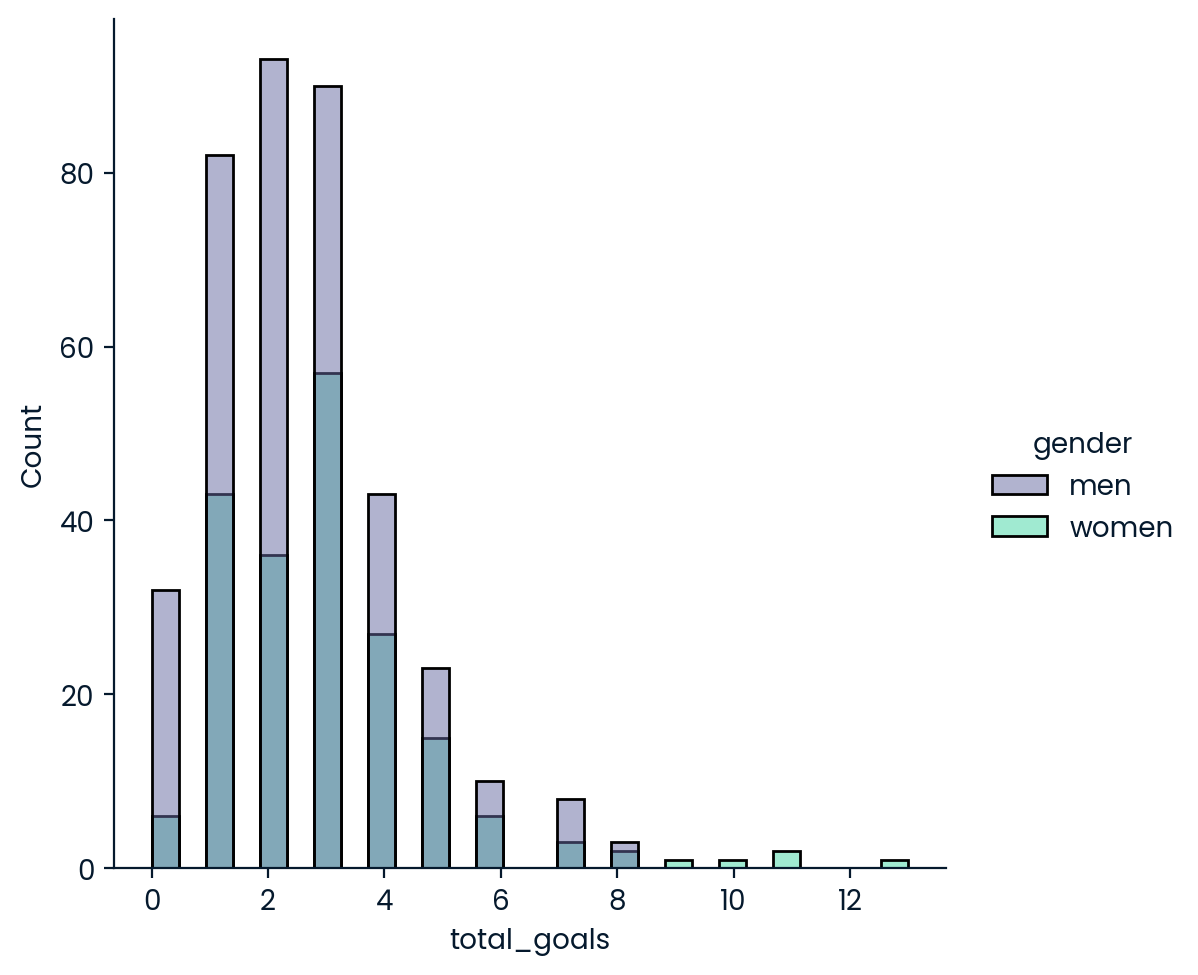

{'p_val': 0.005106609825443641, 'result': 'reject'}


In [4]:
# Start your code here!
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import pingouin

men_results = pd.read_csv('men_results.csv')
women_results = pd.read_csv('women_results.csv')

# 1. Convert the date columns to datetime objects
men_results['date'] = pd.to_datetime(men_results['date'])
women_results['date'] = pd.to_datetime(women_results['date'])
# 2. Filter both tables for World Cup matches after 2002-01-01
men_wc = men_results[(men_results['tournament'] == 'FIFA World Cup') & (men_results['date'] > '2002-01-01')] 
women_wc = women_results[(women_results['tournament'] == 'FIFA World Cup') & (women_results['date'] > '2002-01-01')] 

# calculate the total_goals columns in both of your filtered DataFrames
men_wc['total_goals'] = men_wc['home_score'] + men_wc['away_score']
women_wc['total_goals'] = women_wc['home_score'] + women_wc['away_score']
# Check the Sample Size (n)
print("Men's World Cup Matches:", len(men_wc))
print("Women's World Cup Matches:", len(women_wc))
# Create a combined DataFrame to plot side-by-side histograms
men_wc["gender"] = "men"
women_wc["gender"] = "women"
both_games = pd.concat([men_wc, women_wc])
# Plot histograms for both groups using seaborn
sns.displot(data=both_games,x='total_goals',kind='hist',hue='gender')
plt.show()
# Transform the DataFrame from long-to-wide format
both_games_wide = both_games.pivot(columns="gender", values="total_goals")
# Run the one-tailed Wilcoxon-Mann-Whitney test
# x = group suspected higher (women), y = comparison group (men)
mwu_test = pingouin.mwu(
    x=both_games_wide["women"], y=both_games_wide["men"], alternative="greater"
)
# Subset the column,convert to a numpy array,and extract the float value
p_val = mwu_test['p-val'].values[0]
if p_val <= 0.1:
    result = "reject"
else:
    result = "fail to reject"

 # Package everything into your final target dictionary
result_dict = {"p_val": p_val, "result": result}
print(result_dict)